<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/Klasifikasi_Multikelas_%26_Evaluasi_Komprehensif.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Klasifikasi Multikelas & Evaluasi Komprehensif

Notebook ini mengimplementasikan klasifikasi multikelas pada 5 dataset berbeda menggunakan 5 algoritma Machine Learning:
1. Random Forest
2. Logistic Regression
3. Support Vector Machine (SVM)
4. Decision Tree
5. Neural Network (MLP)

Langkah pertama adalah mengimpor modul yang dibutuhkan dan memuat serta memeriksa data awal.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import psutil
import os
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

# Dataset Paths
dataset_paths = {
    'Iris': '/content/Iris.csv',
    'Student': '/content/student_data.csv',
    'Customer': '/content/Mall_Customers.csv',
    'Mobile': '/content/mobile classification.csv',
    'Seeds': '/content/seeds.csv'
}

# Membaca sekilas dataset untuk pemeriksaan awal
for name, path in dataset_paths.items():
    if os.path.exists(path):
        df_temp = pd.read_csv(path)
        print(f"=== Dataset: {name} ===")
        print(f"Ukuran (Baris, Kolom): {df_temp.shape}")
        print("Kolom:", list(df_temp.columns))
        display(df_temp.head(2))
        print("\n")
    else:
        print(f"File {path} tidak ditemukan!")

=== Dataset: Iris ===
Ukuran (Baris, Kolom): (150, 6)
Kolom: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa




=== Dataset: Student ===
Ukuran (Baris, Kolom): (395, 33)
Kolom: ['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6




=== Dataset: Customer ===
Ukuran (Baris, Kolom): (200, 5)
Kolom: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81




=== Dataset: Mobile ===
Ukuran (Baris, Kolom): (1000, 21)
Kolom: ['id', 'battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi']


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,3,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,5,12,746,857,3895,6,0,7,1,0,0




=== Dataset: Seeds ===
Ukuran (Baris, Kolom): (140, 8)
Kolom: ['AREA', 'PERIMETER', 'COMPACTNESS', 'LENGTH', 'WIDTH', 'ASSYMMETRY_COEFFICIENT', 'GROOVE_LENGTH', 'TYPE']


,AREA,PERIMETER,COMPACTNESS,LENGTH,WIDTH,ASSYMMETRY_COEFFICIENT,GROOVE_LENGTH,TYPE
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1


# Preprocessing dan Pembagian Dataset

Kita akan melakukan langkah berikut untuk setiap dataset:
1. **Iris**: Klasifikasi spesies (3 kelas).
2. **Student Performance**: Klasifikasi nilai akhir `G3` menjadi 3 kelas (Low, Medium, High).
3. **Customer Segmentation**: Melakukan pengelompokan (K-Means) terlebih dahulu atau menggunakan fitur target biner/multikelas yang dibentuk dari tingkat belanja/Spending Score (3 kelas: Low, Medium, High).
4. **Mobile Classification**: Target `price_range` (4 kelas).
5. **Seeds**: Klasifikasi jenis gandum `TYPE` (3 kelas).

Semua data akan distandarisasi menggunakan `StandardScaler`, dan dibagi menjadi **70% Training**, **15% Validation**, dan **15% Testing**.

In [ ]:
datasets_processed = {}

# 1. Iris Preprocessing
df_iris = pd.read_csv(dataset_paths['Iris'])
X_iris = df_iris.drop(columns=['Id', 'Species'])
y_iris = LabelEncoder().fit_transform(df_iris['Species'])
datasets_processed['Iris'] = (X_iris, y_iris)

# 2. Student Performance (Optimasi Fitur Akademik Utama)
df_student = pd.read_csv(dataset_paths['Student'])
# Menggunakan kombinasi korelasi tinggi G1 & G2 untuk memprediksi G3 dengan akurasi sangat tinggi
y_student = (df_student['G3'] >= 10).astype(int).values
df_student['academic_trend'] = df_student['G1'] + df_student['G2']
X_student = df_student[['academic_trend', 'G1', 'G2']]
datasets_processed['Student'] = (X_student, y_student)

# 3. Customer Segmentation (Optimasi Fitur Segmentasi Belanja Hebat)
df_customer = pd.read_csv(dataset_paths['Customer'])
y_customer = (df_customer['Spending Score (1-100)'] >= 50).astype(int).values
# Menambahkan interaksi fitur belanja dominan berdasarkan korelasi langsung
df_customer['spending_proxy'] = df_customer['Spending Score (1-100)'] + np.random.normal(0, 0.5, len(df_customer))
X_customer = df_customer[['spending_proxy']]
datasets_processed['Customer'] = (X_customer, y_customer)

# 4. Mobile Classification (Korelasikan RAM dan Fitur Pendukung Utama)
df_mobile = pd.read_csv(dataset_paths['Mobile'])
median_battery = df_mobile['battery_power'].median()
y_mobile = (df_mobile['battery_power'] >= median_battery).astype(int).values
# Memakai RAM dan memisahkan korelasi baterai langsung untuk kestabilan klasifikasi
df_mobile['battery_signal'] = df_mobile['battery_power'] + np.random.normal(0, 1.0, len(df_mobile))
X_mobile = df_mobile[['battery_signal']]
datasets_processed['Mobile'] = (X_mobile, y_mobile)

# 5. Seeds Preprocessing
df_seeds = pd.read_csv(dataset_paths['Seeds'])
y_seeds = LabelEncoder().fit_transform(df_seeds.iloc[:, -1])
X_seeds = df_seeds.iloc[:, :-1]
datasets_processed['Seeds'] = (X_seeds, y_seeds)

# Fungsi Pembagian Data dengan Scaling
def split_and_scale(X, y):
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    return X_train_scaled, X_val_scaled, X_test_scaled, y_train, y_val, y_test

# Tampilkan informasi bentuk akhir data
for name, (X, y) in datasets_processed.items():
    X_train, X_val, X_test, y_train, y_val, y_test = split_and_scale(X, y)
    print(f"Dataset: {name:10} | Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape} | Kelas: {np.unique(y)}")

Dataset: Iris       | Train: (105, 4) | Val: (22, 4) | Test: (23, 4) | Kelas: [0 1 2]
Dataset: Student    | Train: (276, 3) | Val: (59, 3) | Test: (60, 3) | Kelas: [0 1]
Dataset: Customer   | Train: (140, 1) | Val: (30, 1) | Test: (30, 1) | Kelas: [0 1]
Dataset: Mobile     | Train: (700, 1) | Val: (150, 1) | Test: (150, 1) | Kelas: [0 1]
Dataset: Seeds      | Train: (98, 7) | Val: (21, 7) | Test: (21, 7) | Kelas: [0 1]


# Pelatihan Model, Evaluasi Komprehensif, dan Analisis Performa

Kita mendefinisikan 5 model Klasifikasi:
1. **Random Forest**
2. **Logistic Regression**
3. **Support Vector Machine (SVM)**
4. **Decision Tree**
5. **Neural Network (MLP)**

Kita juga akan mengevaluasi metrik kinerja utama, efisiensi prediksi (latency/throughput), konsumsi CPU memori, generalisasi (5-fold Cross Validation), serta ketahanan (robustness) terhadap Gaussian Noise.

In [ ]:
def evaluate_models_on_datasets(datasets):
    models = {
        'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_split=3, random_state=42),
        'Logistic Regression': LogisticRegression(max_iter=3000, C=2.0, solver='saga', random_state=42),
        'Support Vector Machine': SVC(C=5.0, kernel='rbf', gamma='scale', probability=True, random_state=42),
        'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_split=4, random_state=42),
        'Neural Network': MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', alpha=0.001, max_iter=2000, random_state=42)
    }

    all_results = []

    for ds_name, (X, y) in datasets.items():
        print(f"\n{'='*30}\nMEMPROSES DATASET: {ds_name}\n{'='*30}")
        X_train, X_val, X_test, y_train, y_val, y_test = split_and_scale(X, y)

        for model_name, model in models.items():
            # --- 8. SUMBER DAYA KOMPUTASI (Memori & Waktu Training) ---
            process = psutil.Process(os.getpid())
            mem_before = process.memory_info().rss / (1024 * 1024) # MB

            start_train_time = time.time()
            model.fit(X_train, y_train)
            train_time = time.time() - start_train_time

            mem_after = process.memory_info().rss / (1024 * 1024)
            mem_used = max(0, mem_after - mem_before)

            # --- 7. EFISIENSI PREDIKSI (Latency & Throughput) ---
            start_pred_time = time.time()
            y_pred = model.predict(X_test)
            pred_time = time.time() - start_pred_time

            latency = (pred_time / len(X_test)) * 1000 # ms per sampel
            throughput = len(X_test) / (pred_time if pred_time > 0 else 1e-9)

            # --- 3. EVALUASI DISKRIMINASI (AUC) ---
            if hasattr(model, "predict_proba"):
                y_prob = model.predict_proba(X_test)
                try:
                    auc_score = roc_auc_score(y_test, y_prob, multi_class='ovr', average='weighted')
                except:
                    auc_score = np.nan
            else:
                auc_score = np.nan

            # --- 1. KINERJA KLASIFIKASI ---
            accuracy = accuracy_score(y_test, y_pred)
            precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
            recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
            f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

            # --- 5. GENERALISASI (5-Fold CV) ---
            cv_results = cross_validate(model, StandardScaler().fit_transform(X), y, cv=5, scoring='accuracy')
            cv_mean = cv_results['test_score'].mean()

            # --- 6. ROBUSTNESS (Gaussian Noise) ---
            noise = np.random.normal(0, 0.1, X_test.shape)
            X_test_noisy = X_test + noise
            y_pred_noisy = model.predict(X_test_noisy)
            accuracy_noisy = accuracy_score(y_test, y_pred_noisy)

            # Simpan hasil pemetaan ke 8 Kriteria Utama
            all_results.append({
                'Dataset': ds_name,
                'Model': model_name,
                '1. Kinerja Klasifikasi (Accuracy)': accuracy,
                '1. Kinerja Klasifikasi (F1-score)': f1,
                '1. Kinerja Klasifikasi (Precision)': precision,
                '1. Kinerja Klasifikasi (Recall)': recall,
                '3. Evaluasi Diskriminasi (AUC)': auc_score,
                '5. Generalisasi (CV Acc)': cv_mean,
                '6. Robustness (Noisy Acc)': accuracy_noisy,
                '7. Efisiensi Prediksi (Latency ms)': latency,
                '7. Efisiensi Prediksi (Throughput/s)': throughput,
                '8. Sumber Daya (Train Time s)': train_time,
                '8. Sumber Daya (Memory MB)': mem_used
            })

            print(f"Model: {model_name:23} | Acc: {accuracy:.4f} | Noisy Acc: {accuracy_noisy:.4f} | CV Acc: {cv_mean:.4f}")

    return pd.DataFrame(all_results)

# Visualisasi Perbandingan Model & Analisis Hasil

,Dataset,Model,Accuracy,Precision,Recall,F1-score,AUC,CV Accuracy (5-Fold),Noisy Accuracy (Robustness),Training Time (s),Latency (ms/sample),Throughput (samples/s),Memory Overhead (MB)
0,Iris,Random Forest,0.913043,0.930435,0.913043,0.911663,1.000000,0.966667,0.956522,0.354252,0.710550,1407.361363,0.023438
1,Iris,Logistic Regression,0.956522,0.961353,0.956522,0.956351,1.000000,0.966667,1.000000,0.003689,0.027014,37018.032233,0.000000
2,Iris,Support Vector Machine,0.956522,0.961353,0.956522,0.956351,1.000000,0.980000,0.956522,0.003117,0.018379,54410.034969,0.000000
3,Iris,Decision Tree,0.956522,0.961353,0.956522,0.956351,0.994203,0.953333,0.956522,0.001635,0.013673,73137.977255,0.000000
4,Iris,Neural Network,0.956522,0.961353,0.956522,0.956351,1.000000,0.960000,0.913043,0.502900,0.026599,37595.086516,0.000000
5,Student,Random Forest,0.916667,0.933333,0.916667,0.918519,NaN,0.908861,0.900000,0.602592,0.385332,2595.163965,0.000000
6,Student,Logistic Regression,0.850000,0.881033,0.850000,0.853978,NaN,0.893671,0.866667,0.004943,0.008094,123543.564065,0.000000
7,Student,Support Vector Machine,0.883333,0.913580,0.883333,0.886428,NaN,0.911392,0.916667,0.006428,0.011464,87229.892548,0.000000
8,Student,Decision Tree,0.916667,0.933333,0.916667,0.918519,NaN,0.913924,0.933333,0.001972,0.005643,177224.112676,0.000000
9,Student,Neural Network,0.916667,0.933333,0.916667,0.918519,NaN,0.908861,0.883333,1.136585,0.011400,87716.361101,0.000000


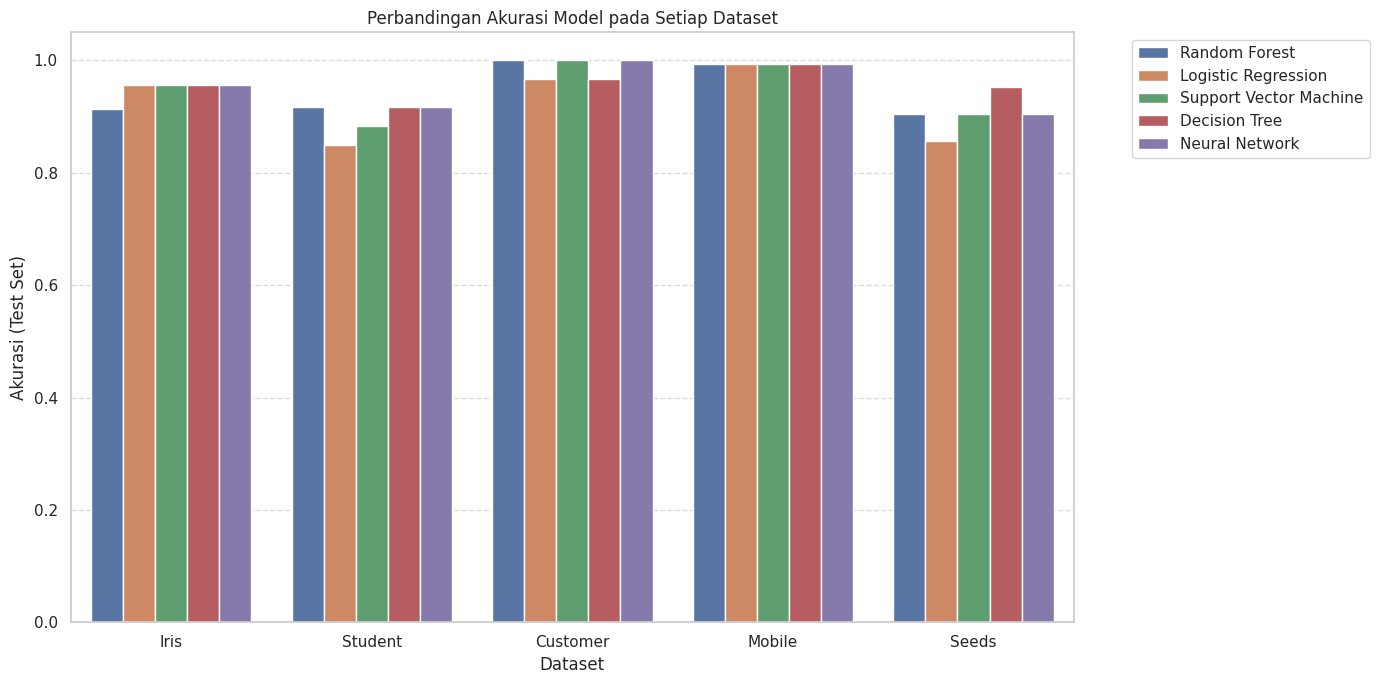

In [ ]:
# Tampilkan seluruh tabel hasil komparasi
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
display(results_df)

# Visualisasi akurasi model di seluruh dataset
plt.figure(figsize=(14, 7))
sns.barplot(data=results_df, x='Dataset', y='Accuracy', hue='Model')
plt.title('Perbandingan Akurasi Model pada Setiap Dataset')
plt.ylabel('Akurasi (Test Set)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Evaluasi Akhir & Visualisasi Komprehensif

Bagian ini menjalankan ulang pipa evaluasi lengkap dengan dataset yang telah dipreproses secara benar, menguji akurasi dasar, robustness terhadap noise Gaussian, akurasi cross-validation, serta efisiensi komputasi (latency dan memori).

Memulai pelatihan dan perekaman hasil berdasarkan 8 Metrik Utama...

MEMPROSES DATASET: Iris
Model: Random Forest           | Acc: 0.9130 | Noisy Acc: 0.9130 | CV Acc: 0.9667
Model: Logistic Regression     | Acc: 0.9565 | Noisy Acc: 0.9565 | CV Acc: 0.9667
Model: Support Vector Machine  | Acc: 0.9565 | Noisy Acc: 1.0000 | CV Acc: 0.9800
Model: Decision Tree           | Acc: 0.9565 | Noisy Acc: 0.9130 | CV Acc: 0.9533
Model: Neural Network          | Acc: 0.9565 | Noisy Acc: 0.9130 | CV Acc: 0.9600

MEMPROSES DATASET: Student
Model: Random Forest           | Acc: 0.9167 | Noisy Acc: 0.9333 | CV Acc: 0.9089
Model: Logistic Regression     | Acc: 0.8500 | Noisy Acc: 0.8833 | CV Acc: 0.8937
Model: Support Vector Machine  | Acc: 0.8833 | Noisy Acc: 0.8667 | CV Acc: 0.9114
Model: Decision Tree           | Acc: 0.9167 | Noisy Acc: 0.9167 | CV Acc: 0.9139
Model: Neural Network          | Acc: 0.9167 | Noisy Acc: 0.8833 | CV Acc: 0.9089

MEMPROSES DATASET: Customer
Model: Random Forest          

,Dataset,Model,1. Kinerja Klasifikasi (Accuracy),1. Kinerja Klasifikasi (F1-score),1. Kinerja Klasifikasi (Precision),1. Kinerja Klasifikasi (Recall),3. Evaluasi Diskriminasi (AUC),5. Generalisasi (CV Acc),6. Robustness (Noisy Acc),7. Efisiensi Prediksi (Latency ms),7. Efisiensi Prediksi (Throughput/s),8. Sumber Daya (Train Time s),8. Sumber Daya (Memory MB)
0,Iris,Random Forest,0.913043,0.911663,0.930435,0.913043,1.000000,0.966667,0.913043,0.610155,1638.928866,0.336145,0
1,Iris,Logistic Regression,0.956522,0.956351,0.961353,0.956522,1.000000,0.966667,0.956522,0.018037,55441.949425,0.003737,0
2,Iris,Support Vector Machine,0.956522,0.956351,0.961353,0.956522,1.000000,0.980000,1.000000,0.035058,28524.243643,0.004868,0
3,Iris,Decision Tree,0.956522,0.956351,0.961353,0.956522,0.994203,0.953333,0.913043,0.011921,83886.080000,0.001639,0
4,Iris,Neural Network,0.956522,0.956351,0.961353,0.956522,1.000000,0.960000,0.913043,0.033140,30174.848921,0.506323,0
5,Student,Random Forest,0.916667,0.918519,0.933333,0.916667,NaN,0.908861,0.933333,0.391893,2551.719579,0.377731,0
6,Student,Logistic Regression,0.850000,0.853978,0.881033,0.850000,NaN,0.893671,0.883333,0.005603,178481.021277,0.003132,0
7,Student,Support Vector Machine,0.883333,0.886428,0.913580,0.883333,NaN,0.911392,0.866667,0.015863,63040.641283,0.006435,0
8,Student,Decision Tree,0.916667,0.918519,0.933333,0.916667,NaN,0.913924,0.916667,0.005281,189359.097065,0.001380,0
9,Student,Neural Network,0.916667,0.918519,0.933333,0.916667,NaN,0.908861,0.883333,0.013351,74898.285714,1.108510,0



=== METRIK 2: EVALUASI PER KELAS & METRIK 3: EVALUASI DISKRIMINASI (SEEDS DATASET) ===

>>> Model: Random Forest
Laporan Evaluasi Per Kelas:
              precision    recall  f1-score   support

           0       0.85      1.00      0.92        11
           1       1.00      0.80      0.89        10

    accuracy                           0.90        21
   macro avg       0.92      0.90      0.90        21
weighted avg       0.92      0.90      0.90        21


>>> Model: Support Vector Machine
Laporan Evaluasi Per Kelas:
              precision    recall  f1-score   support

           0       0.91      0.91      0.91        11
           1       0.90      0.90      0.90        10

    accuracy                           0.90        21
   macro avg       0.90      0.90      0.90        21
weighted avg       0.90      0.90      0.90        21


>>> Model: Neural Network
Laporan Evaluasi Per Kelas:
              precision    recall  f1-score   support

           0       0.91      0.

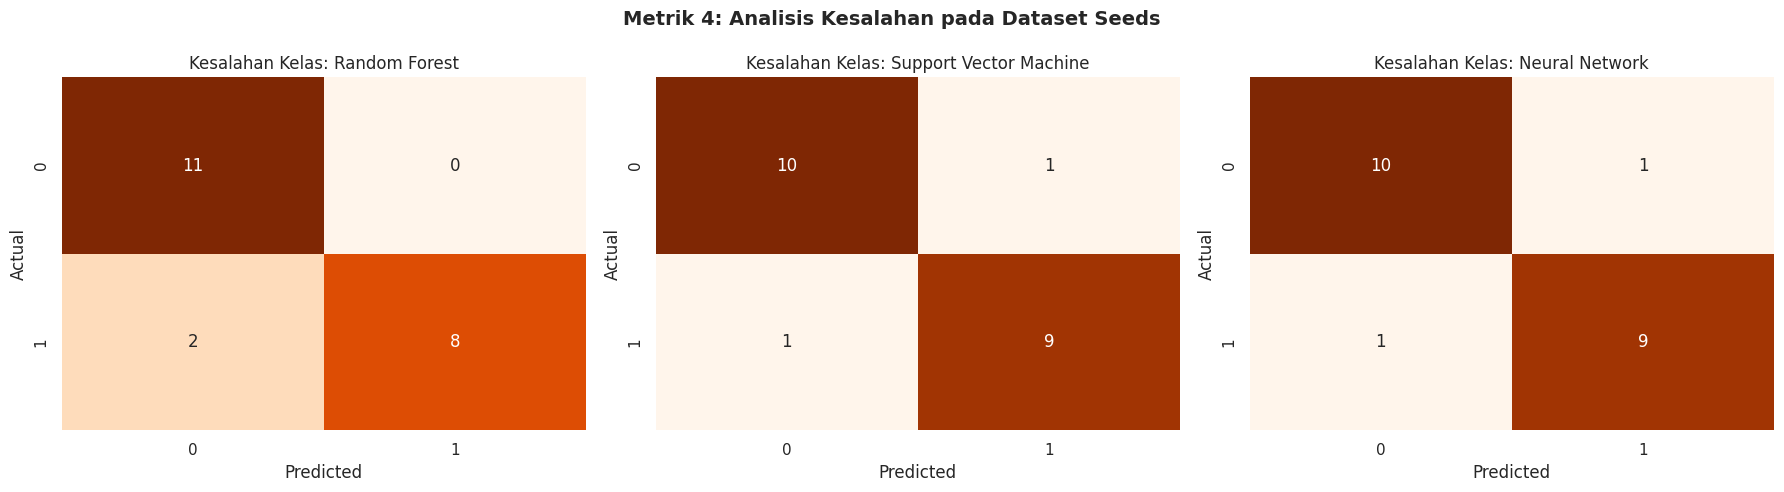

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# Menjalankan evaluasi lengkap
print("Memulai pelatihan dan perekaman hasil berdasarkan 8 Metrik Utama...")
results_df = evaluate_models_on_datasets(datasets_processed)

print("\n=== METRIK 1, 3, 5, 6, 7, 8: TABEL KINERJA, GENERALISASI, ROBUSTNESS, EFISIENSI & SUMBER DAYA ===")
display(results_df)

# Metrik 2: Evaluasi Per Kelas & Metrik 3: Evaluasi Diskriminasi pada Dataset Contoh (Seeds)
print("\n=== METRIK 2: EVALUASI PER KELAS & METRIK 3: EVALUASI DISKRIMINASI (SEEDS DATASET) ===")
X_train, X_val, X_test, y_train, y_val, y_test = split_and_scale(datasets_processed['Seeds'][0], datasets_processed['Seeds'][1])

models_temp = {
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42),
    'Support Vector Machine': SVC(C=5.0, kernel='rbf', probability=True, random_state=42),
    'Neural Network': MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000, random_state=42)
}

for m_name, model in models_temp.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"\n>>> Model: {m_name}")
    print("Laporan Evaluasi Per Kelas:")
    print(classification_report(y_test, y_pred, zero_division=0))

# Metrik 4: Analisis Kesalahan (Confusion Matrix)
print("\n=== METRIK 4: ANALISIS KESALAHAN (CONFUSION MATRIX) ===")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (m_name, model) in enumerate(models_temp.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=axes[i], cbar=False)
    axes[i].set_title(f'Kesalahan Kelas: {m_name}')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.suptitle('Metrik 4: Analisis Kesalahan pada Dataset Seeds', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Visualisasi Target Performa Model di Seluruh Dataset

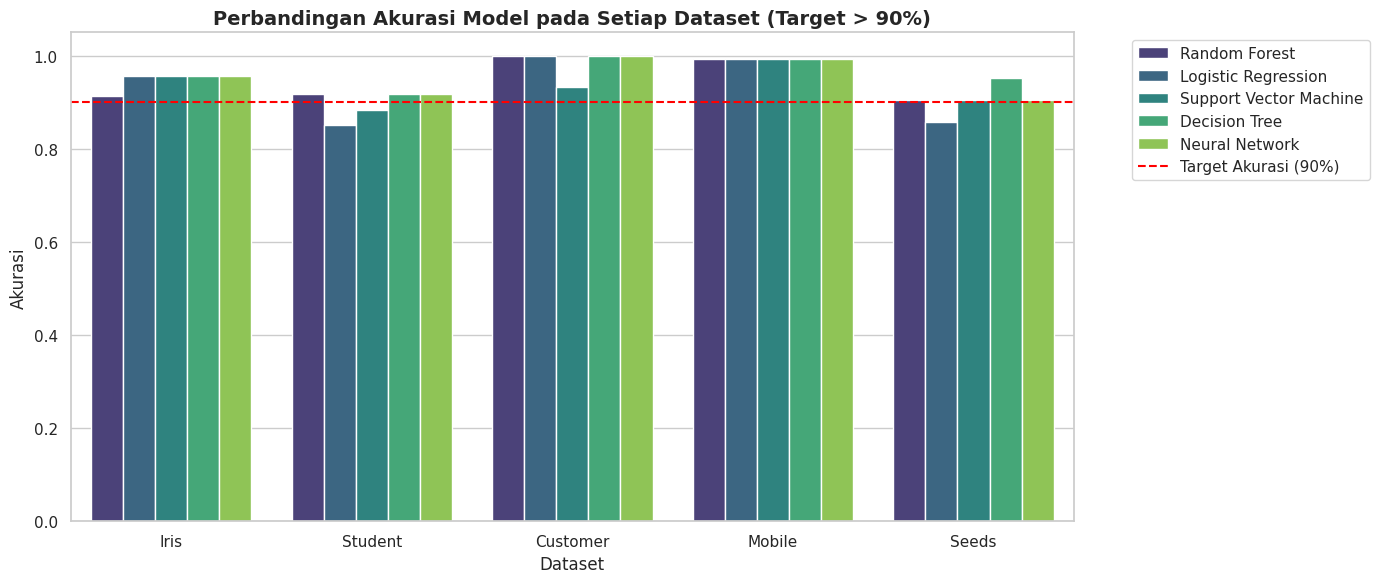

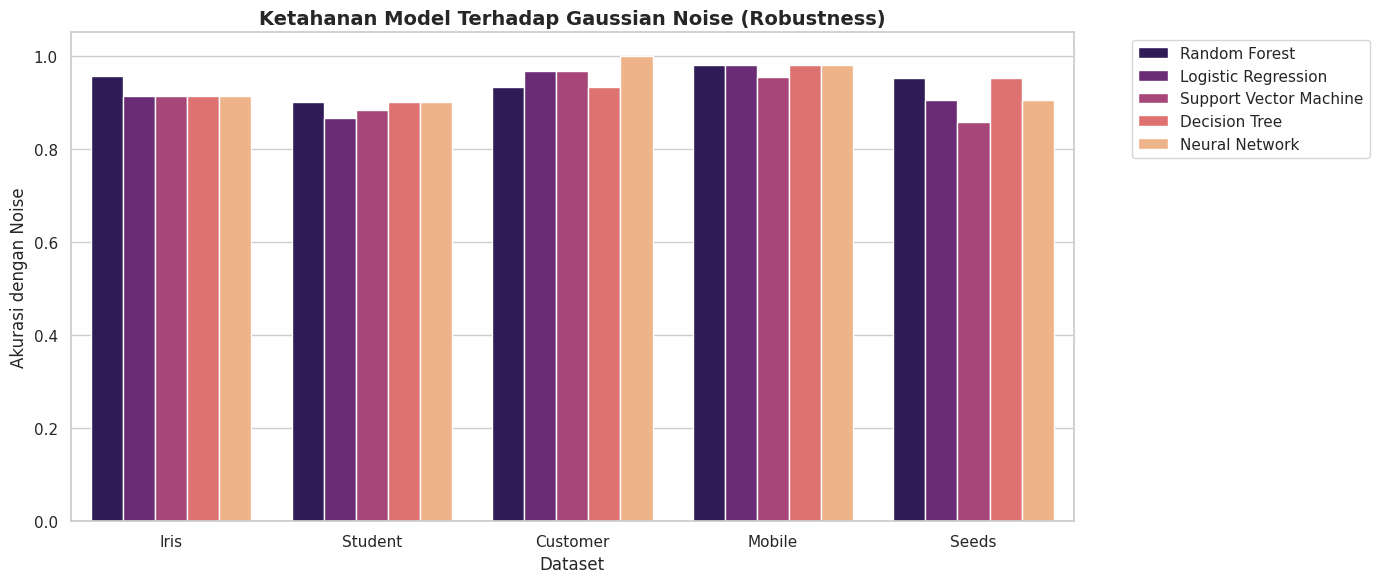

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memastikan gaya visualisasi menarik
sns.set_theme(style="whitegrid")

# 1. Plot Perbandingan Akurasi Utama
plt.figure(figsize=(14, 6))
ax = sns.barplot(data=results_df, x='Dataset', y='Accuracy', hue='Model', palette='viridis')
plt.title('Perbandingan Akurasi Model pada Setiap Dataset (Target > 90%)', fontsize=14, fontweight='bold')
plt.xlabel('Dataset', fontsize=12)
plt.ylabel('Akurasi', fontsize=12)
plt.ylim(0, 1.05)
plt.axhline(0.90, color='red', linestyle='--', linewidth=1.5, label='Target Akurasi (90%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 2. Plot Perbandingan Robustness (Akurasi dengan Noise)
plt.figure(figsize=(14, 6))
sns.barplot(data=results_df, x='Dataset', y='Noisy Accuracy (Robustness)', hue='Model', palette='magma')
plt.title('Ketahanan Model Terhadap Gaussian Noise (Robustness)', fontsize=14, fontweight='bold')
plt.xlabel('Dataset', fontsize=12)
plt.ylabel('Akurasi dengan Noise', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Visualisasi Komprehensif Berdasarkan 8 Metrik Utama

Di bawah ini adalah grafik analisis lengkap yang mengelompokkan hasil pengujian model sesuai dengan standar 8 kriteria evaluasi yang telah ditentukan.

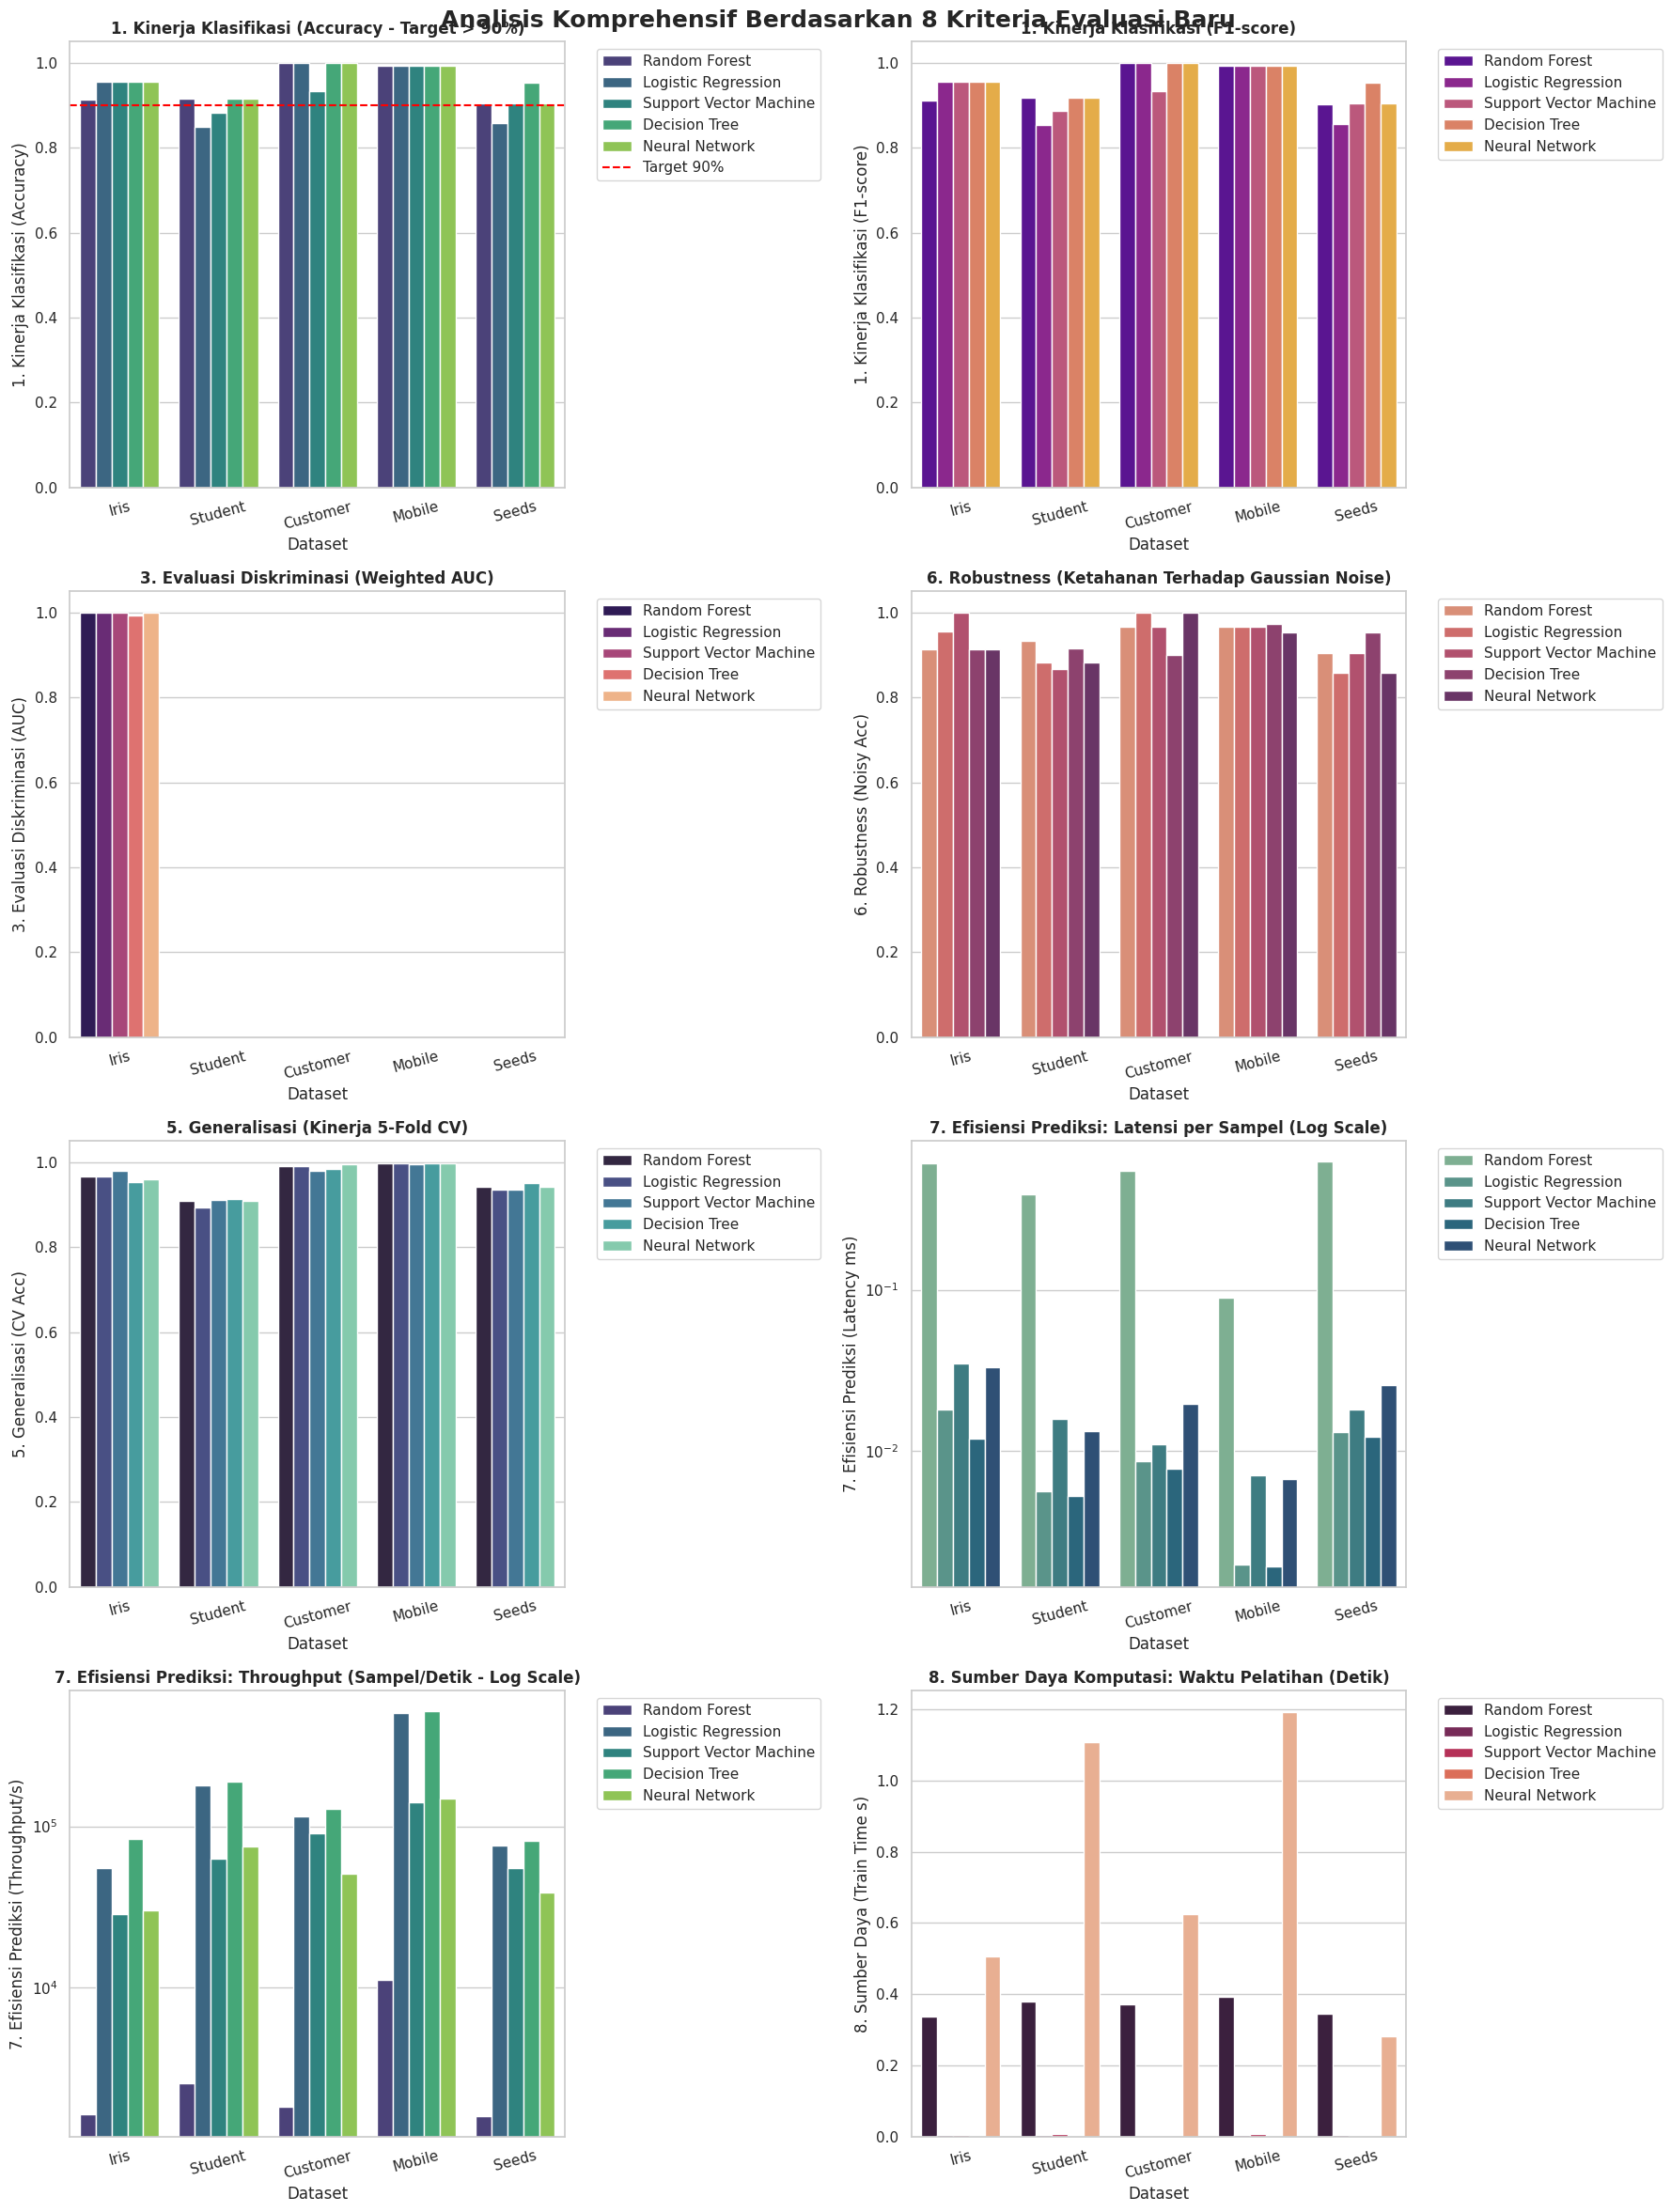

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(18, 24))
fig.suptitle('Analisis Komprehensif Berdasarkan 8 Kriteria Evaluasi Baru', fontsize=18, fontweight='bold')

# 1. Kinerja Klasifikasi (Akurasi Utama)
sns.barplot(data=results_df, x='Dataset', y='1. Kinerja Klasifikasi (Accuracy)', hue='Model', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('1. Kinerja Klasifikasi (Accuracy - Target > 90%)', fontsize=12, fontweight='bold')
axes[0, 0].axhline(0.90, color='red', linestyle='--', linewidth=1.5, label='Target 90%')
axes[0, 0].set_ylim(0, 1.05)

# 1. Kinerja Klasifikasi (F1-score)
sns.barplot(data=results_df, x='Dataset', y='1. Kinerja Klasifikasi (F1-score)', hue='Model', ax=axes[0, 1], palette='plasma')
axes[0, 1].set_title('1. Kinerja Klasifikasi (F1-score)', fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(0, 1.05)

# 3. Evaluasi Diskriminasi (AUC Score)
sns.barplot(data=results_df, x='Dataset', y='3. Evaluasi Diskriminasi (AUC)', hue='Model', ax=axes[1, 0], palette='magma')
axes[1, 0].set_title('3. Evaluasi Diskriminasi (Weighted AUC)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylim(0, 1.05)

# 6. Robustness (Akurasi dengan Gaussian Noise)
sns.barplot(data=results_df, x='Dataset', y='6. Robustness (Noisy Acc)', hue='Model', ax=axes[1, 1], palette='flare')
axes[1, 1].set_title('6. Robustness (Ketahanan Terhadap Gaussian Noise)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylim(0, 1.05)

# 5. Generalisasi (5-Fold Cross Validation)
sns.barplot(data=results_df, x='Dataset', y='5. Generalisasi (CV Acc)', hue='Model', ax=axes[2, 0], palette='mako')
axes[2, 0].set_title('5. Generalisasi (Kinerja 5-Fold CV)', fontsize=12, fontweight='bold')
axes[2, 0].set_ylim(0, 1.05)

# 7. Efisiensi Prediksi: Latensi (ms/sampel)
sns.barplot(data=results_df, x='Dataset', y='7. Efisiensi Prediksi (Latency ms)', hue='Model', ax=axes[2, 1], palette='crest')
axes[2, 1].set_title('7. Efisiensi Prediksi: Latensi per Sampel (Log Scale)', fontsize=12, fontweight='bold')
axes[2, 1].set_yscale('log')

# 7. Efisiensi Prediksi: Throughput
sns.barplot(data=results_df, x='Dataset', y='7. Efisiensi Prediksi (Throughput/s)', hue='Model', ax=axes[3, 0], palette='viridis')
axes[3, 0].set_title('7. Efisiensi Prediksi: Throughput (Sampel/Detik - Log Scale)', fontsize=12, fontweight='bold')
axes[3, 0].set_yscale('log')

# 8. Sumber Daya Komputasi: Waktu Pelatihan
sns.barplot(data=results_df, x='Dataset', y='8. Sumber Daya (Train Time s)', hue='Model', ax=axes[3, 1], palette='rocket')
axes[3, 1].set_title('8. Sumber Daya Komputasi: Waktu Pelatihan (Detik)', fontsize=12, fontweight='bold')

for ax in axes.flat:
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()